> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M-33-CD Javier Bueno Sánchez.

**Conceptos avanzados de estadística: análisis del precio de viviendas.**

**Preámbulo.**

El objetivo es estudiar la distribución de variables relevantes del mercado inmobiliario y construir un modelo de regresión lineal para explicar y predecir `SalePrice`. El desarrollo combina evidencia visual y analítica, interpretación estadística y evaluación fuera de muestra.

Una precisión metodológica: la regresión lineal no exige que cada variable explicativa sea normal. Para la inferencia interesa especialmente revisar los residuos; por ello, la normalidad de las variables se presenta como análisis descriptivo y la de los residuos como diagnóstico del modelo.

**Índice.**

1. Objetivo y metodología.  
2. Librerías y carga de datos.  
3. Validación de la base.  
4. Análisis descriptivo y pruebas de normalidad.  
5. Correlaciones y heatmap.  
6. Modelo OLS inicial con variables numéricas.  
7. Significancia estadística.  
8. Multicolinealidad mediante VIF.  
9. Selección del modelo final.  
10. Evaluación predictiva.  
11. Diagnóstico de residuos . 
12. Conclusiones.

**1. Objetivo y metodología.**

Se seguirá este flujo:

- revisar estructura, tipos, faltantes y duplicados;
- describir `SalePrice`, `GrLivArea` y `2ndFlrSF` con media, varianza, desviación estándar y cuartiles;
- evaluar sus distribuciones mediante histogramas, boxplots, Q-Q plots, Shapiro-Wilk y Kolmogorov-Smirnov;
- calcular correlaciones entre variables numéricas y visualizar las relaciones más relevantes;
- estimar un OLS inicial con todos los predictores numéricos utilizables;
- revisar valores p y VIF para retirar variables no significativas o redundantes;
- evaluar el modelo final en un conjunto de prueba mediante MSE, RMSE y $R^2$;
- revisar linealidad, homocedasticidad y normalidad de los residuos.

`Id` se excluye de los predictores porque es un identificador, no una característica económica o física de la vivienda.

In [1]:
# Si alguna librería no está instalada, descomentar y ejecutar una sola vez:
# %pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn.

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", palette="Blues_d")

**2. Carga de datos.**

In [2]:
# Búsqueda flexible para conservar la reproducibilidad si cambia el sufijo del archivo.
rutas = [Path("House Pricing(1).csv"),
         Path("House Pricing.csv"),
         Path("upload/House Pricing(1).csv"),
         Path("House Pricing(1).csv"),]

ruta_csv = next((ruta for ruta in rutas if ruta.exists()), None)
if ruta_csv is None:
    raise FileNotFoundError("Coloca 'House Pricing(1).csv' junto al notebook.")

df = pd.read_csv(ruta_csv, na_values=["NA"])
print(f"Archivo: {ruta_csv}")
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
display(df.head())

Archivo: House Pricing.csv
Dimensiones: 1,460 filas x 81 columnas


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0000,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.0000",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0000,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.0000",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0000,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.0000",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0000,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0000,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.0000",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0000,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0000,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.0000",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**3. Validación de la base.**

In [3]:
resumen_base = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean().mul(100),
    "valores_unicos": df.nunique(dropna=False),
}).sort_values("porcentaje_nulos", ascending=False)

print(f"Filas duplicadas completas: {df.duplicated().sum()}")
print(f"Identificadores duplicados: {df['Id'].duplicated().sum()}")
print(f"Variables numéricas: {df.select_dtypes(include=np.number).shape[1]}")
print(f"Variables categóricas: {df.select_dtypes(exclude=np.number).shape[1]}")
display(resumen_base.head(15))

Filas duplicadas completas: 0
Identificadores duplicados: 0
Variables numéricas: 38
Variables categóricas: 43


,tipo,nulos,porcentaje_nulos,valores_unicos
PoolQC,object,1453,99.5205,4
MiscFeature,object,1406,96.3014,5
Alley,object,1369,93.7671,3
Fence,object,1179,80.7534,5
MasVnrType,object,872,59.7260,4
FireplaceQu,object,690,47.2603,6
LotFrontage,float64,259,17.7397,111
GarageQual,object,81,5.5479,6
GarageFinish,object,81,5.5479,4
GarageType,object,81,5.5479,7


La base contiene 1,460 operaciones y 81 variables. Hay 38 columnas numéricas, incluida la respuesta `SalePrice`. Los faltantes numéricos se concentran principalmente en `LotFrontage`, `GarageYrBlt` y `MasVnrArea`. Para no perder observaciones, se imputarán mediante la mediana. En la evaluación predictiva, el imputador se ajustará exclusivamente con el conjunto de entrenamiento para evitar fuga de información.

**4. Análisis descriptivo y pruebas de normalidad.**

In [4]:
variables_objetivo = ["SalePrice", "GrLivArea", "2ndFlrSF"]

descriptivos = pd.DataFrame({
    "n": df[variables_objetivo].count(),
    "media": df[variables_objetivo].mean(),
    "varianza_muestral": df[variables_objetivo].var(ddof=1),
    "desviacion_estandar": df[variables_objetivo].std(ddof=1),
    "minimo": df[variables_objetivo].min(),
    "Q1": df[variables_objetivo].quantile(0.25),
    "mediana_Q2": df[variables_objetivo].median(),
    "Q3": df[variables_objetivo].quantile(0.75),
    "maximo": df[variables_objetivo].max(),
    "asimetria": df[variables_objetivo].skew(),}).T

display(descriptivos)

,SalePrice,GrLivArea,2ndFlrSF
n,"1,460.0000","1,460.0000","1,460.0000"
media,"180,921.1959","1,515.4637",346.9925
varianza_muestral,"6,311,111,264.2975","276,129.6334","190,557.0753"
desviacion_estandar,"79,442.5029",525.4804,436.5284
minimo,"34,900.0000",334.0000,0.0000
Q1,"129,975.0000","1,129.5000",0.0000
mediana_Q2,"163,000.0000","1,464.0000",0.0000
Q3,"214,000.0000","1,776.7500",728.0000
maximo,"755,000.0000","5,642.0000","2,065.0000"
asimetria,1.8829,1.3666,0.8130


Resultados centrales esperados:


| Variable | Media | Desv. estándar | Q1 | Mediana | Q3 | Asimetría |
|---|---:|---:|---:|---:|---:|---:|
| SalePrice | 180,921.20 | 79,442.50 | 129,975.00 | 163,000.00 | 214,000.00 | 1.883 |
| GrLivArea | 1,515.46 | 525.48 | 1,129.50 | 1,464.00 | 1,776.75 | 1.367 |
| 2ndFlrSF | 346.99 | 436.53 | 0.00 | 0.00 | 728.00 | 0.813 |


Las tres distribuciones presentan asimetría positiva. `2ndFlrSF` contiene muchos ceros porque numerosas viviendas no tienen segundo piso; por su naturaleza, no es razonable esperar una distribución normal continua.

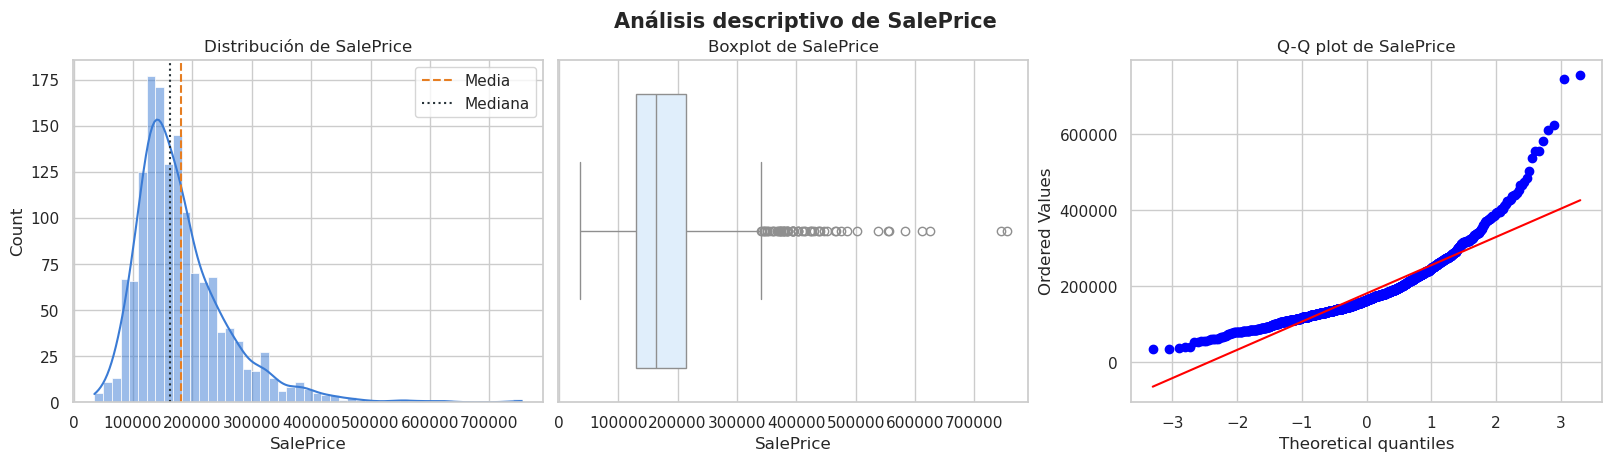

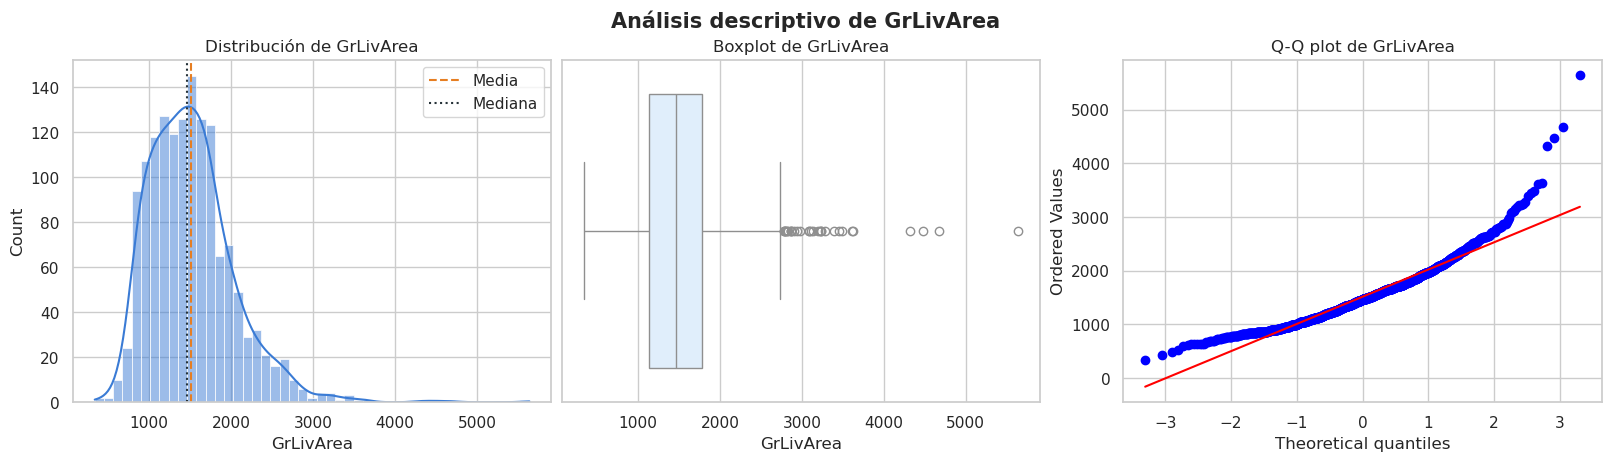

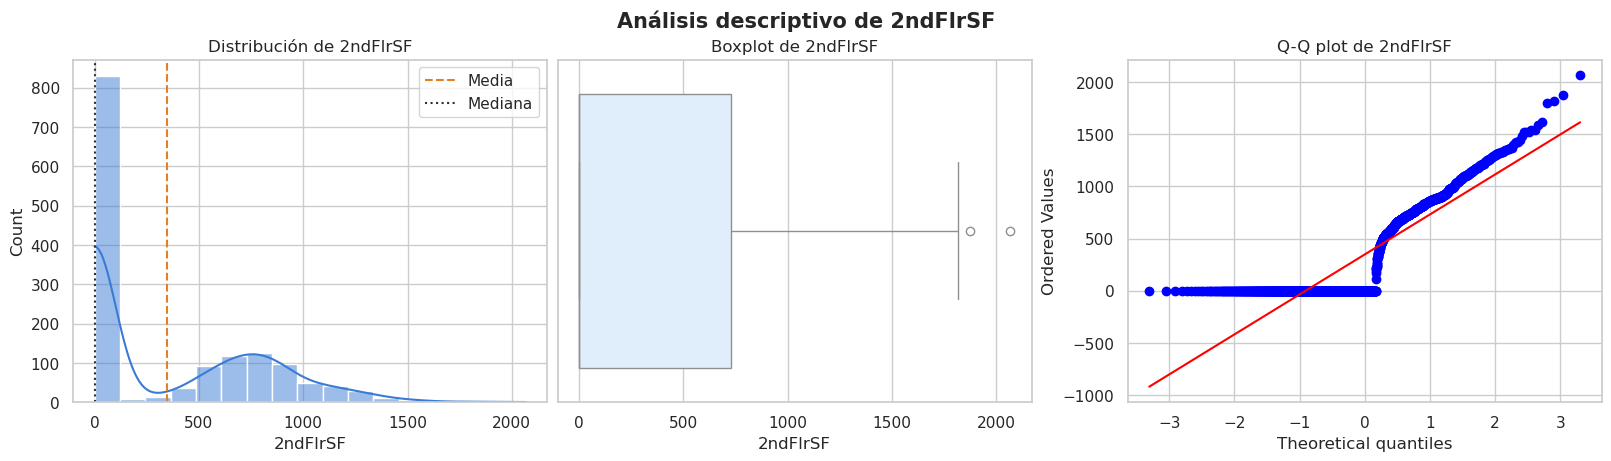

In [30]:
for variable in variables_objetivo:
    serie = df[variable].dropna()
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

    sns.histplot(serie, kde=True, ax=axes[0], color="#3A7BD5")
    axes[0].axvline(serie.mean(), color="#E67E22", linestyle="--", label="Media")
    axes[0].axvline(serie.median(), color="#263238", linestyle=":", label="Mediana")
    axes[0].set_title(f"Distribución de {variable}")
    axes[0].legend()

    sns.boxplot(x=serie, ax=axes[1], color="#DCEEFF")
    axes[1].set_title(f"Boxplot de {variable}")
    axes[1].set_xlabel(variable)

    stats.probplot(serie, dist="norm", plot=axes[2])
    axes[2].set_title(f"Q-Q plot de {variable}")

    fig.suptitle(f"Análisis descriptivo de {variable}", fontsize=15, fontweight="bold")
    plt.show()



In [6]:
resultados_normalidad = []

for variable in variables_objetivo:
    serie = df[variable].dropna()
    shapiro_stat, shapiro_p = stats.shapiro(serie)

    # KS sobre datos estandarizados. Al estimar media y desviación con la misma muestra,
    # el p-valor debe interpretarse con cautela; el resultado se complementa con Q-Q plot.
    z = (serie - serie.mean()) / serie.std(ddof=1)
    ks_stat, ks_p = stats.kstest(z, "norm")

    resultados_normalidad.append({
        "variable": variable,
        "Shapiro_W": shapiro_stat,
        "Shapiro_p": shapiro_p,
        "KS_D": ks_stat,
        "KS_p": ks_p,
        "decision_Shapiro_5%": "Rechazar normalidad" if shapiro_p < 0.05 else "No rechazar normalidad",
        "decision_KS_5%": "Rechazar normalidad" if ks_p < 0.05 else "No rechazar normalidad",})

normalidad = pd.DataFrame(resultados_normalidad).set_index("variable")
display(normalidad)

,Shapiro_W,Shapiro_p,KS_D,KS_p,decision_Shapiro_5%,decision_KS_5%
variable,,,,,,
SalePrice,0.8697,0.0000,0.1237,0.0000,Rechazar normalidad,Rechazar normalidad
GrLivArea,0.9280,0.0000,0.0675,0.0000,Rechazar normalidad,Rechazar normalidad
2ndFlrSF,0.7668,0.0000,0.3545,0.0000,Rechazar normalidad,Rechazar normalidad


**Interpretación.** Con $\alpha=0.05$, Shapiro-Wilk rechaza la hipótesis de normalidad en las tres variables. La evidencia visual coincide: colas derechas, valores extremos y, en `2ndFlrSF`, una masa de observaciones en cero. Con muestras grandes, las pruebas pueden detectar desviaciones pequeñas; aquí las desviaciones también son materialmente visibles, por lo que la conclusión no depende únicamente del valor p.

**5. Correlaciones y heatmap.**

,correlacion_con_SalePrice
OverallQual,0.7910
GrLivArea,0.7086
GarageCars,0.6404
GarageArea,0.6234
TotalBsmtSF,0.6136
1stFlrSF,0.6059
FullBath,0.5607
TotRmsAbvGrd,0.5337
YearBuilt,0.5229
YearRemodAdd,0.5071


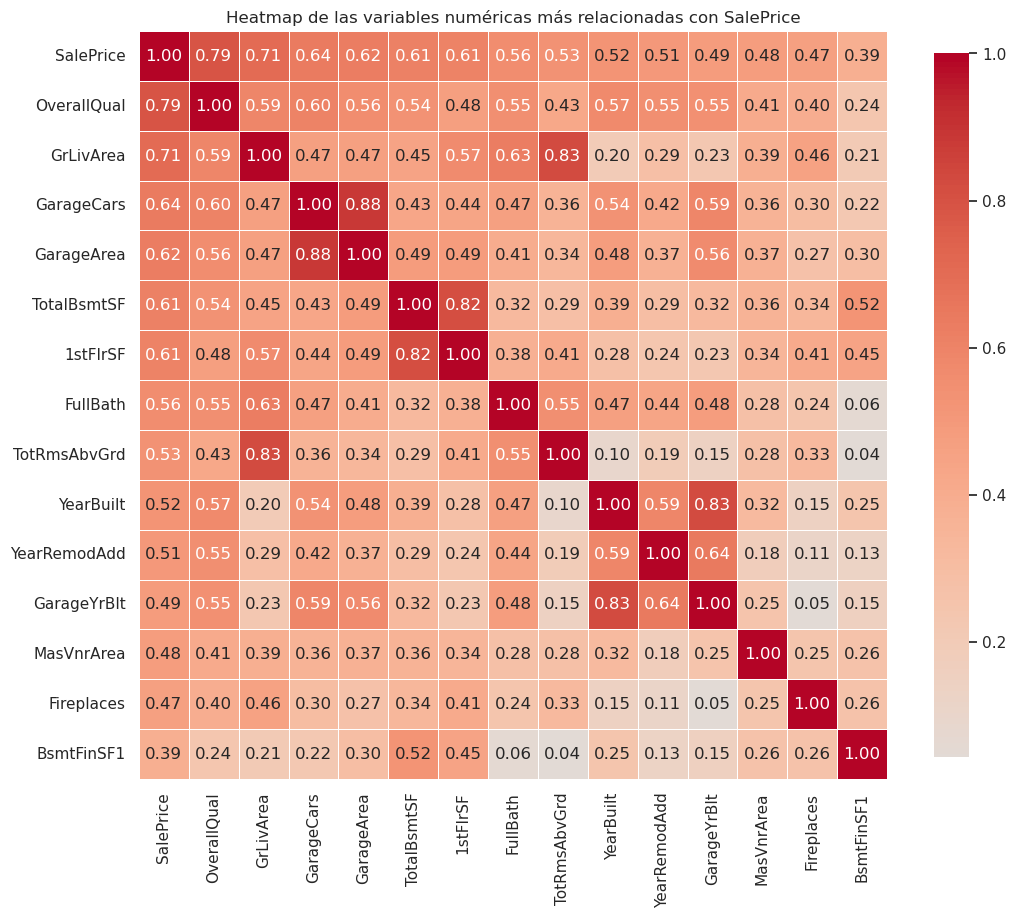

In [42]:
numericas = df.select_dtypes(include=np.number)
correlaciones = numericas.corr(method="pearson")

corr_precio = (
    correlaciones["SalePrice"]
    .drop("SalePrice")
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .rename("correlacion_con_SalePrice")
    .to_frame())
display(corr_precio.head(15))

top_variables = ["SalePrice"] + corr_precio.head(14).index.tolist()
plt.figure(figsize=(11, 10))
sns.heatmap(
    correlaciones.loc[top_variables, top_variables],
    cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True,
    linewidths=0.5, cbar_kws={"shrink": 0.8})

plt.title("Heatmap de las variables numéricas más relacionadas con SalePrice")
plt.tight_layout()
plt.show()

Las mayores correlaciones lineales con `SalePrice` son `OverallQual` (0.791), `GrLivArea` (0.709), `GarageCars` (0.640), `GarageArea` (0.623), `TotalBsmtSF` (0.614) y `1stFlrSF` (0.606). En términos de negocio, precio aumenta principalmente con calidad general, superficie habitable, capacidad de garaje y superficie construida. Correlación no implica causalidad y tampoco garantiza que un coeficiente siga siendo significativo al controlar simultáneamente las demás variables.

**6. Modelo OLS inicial con todas las variables numéricas.**

In [8]:
y = df["SalePrice"].copy()
X = df.select_dtypes(include=np.number).drop(columns=["SalePrice", "Id"])

imputador_inicial = SimpleImputer(strategy="median")
X_imputada = pd.DataFrame(imputador_inicial.fit_transform(X), columns=X.columns, index=X.index)

X_ols = sm.add_constant(X_imputada, has_constant="add")
modelo_inicial = sm.OLS(y, X_ols).fit()
print(modelo_inicial.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.813
Model:                            OLS   Adj. R-squared:                  0.809
Method:                 Least Squares   F-statistic:                     182.4
Date:                Thu, 06 Aug 2026   Prob (F-statistic):               0.00
Time:                        15:36:21   Log-Likelihood:                -17319.
No. Observations:                1460   AIC:                         3.471e+04
Df Residuals:                    1425   BIC:                         3.489e+04
Df Model:                          34                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          4.628e+05   1.41e+06      0.327

El modelo inicial utiliza los 36 predictores numéricos disponibles después de retirar `Id`. Su $R^2$ esperado es aproximadamente 0.813 y su $R^2$ ajustado, cercano a 0.808. El modelo global resulta significativo, pero algunos coeficientes individuales presentan valores p superiores a 0.05. Mantenerlos sin revisión complicaría la interpretación y podría aumentar la inestabilidad de los coeficientes.

**7. Significancia estadística.**

In [9]:
tabla_coeficientes = pd.DataFrame({
    "coeficiente": modelo_inicial.params,
    "error_estandar": modelo_inicial.bse,
    "t": modelo_inicial.tvalues,
    "p_valor": modelo_inicial.pvalues,
    "IC_95_inf": modelo_inicial.conf_int()[0],
    "IC_95_sup": modelo_inicial.conf_int()[1],}).drop(index="const").sort_values("p_valor")

tabla_coeficientes["significativa_5%"] = tabla_coeficientes["p_valor"] < 0.05
display(tabla_coeficientes)
print("Variables significativas al 5%:", tabla_coeficientes["significativa_5%"].sum())
print("Variables no significativas al 5%:", (~tabla_coeficientes["significativa_5%"]).sum())

,coeficiente,error_estandar,t,p_valor,IC_95_inf,IC_95_sup,significativa_5%
OverallQual,"17,332.9321","1,187.4461",14.5968,0.0000,"15,003.6021","19,662.2620",True
MSSubClass,-181.7077,27.6736,-6.5661,0.0000,-235.9931,-127.4223,True
BedroomAbvGr,"-10,092.6383","1,701.6282",-5.9312,0.0000,"-13,430.6035","-6,754.6732",True
GrLivArea,30.8231,5.7036,5.4042,0.0000,19.6347,42.0114,True
MasVnrArea,31.3445,5.9330,5.2831,0.0000,19.7062,42.9828,True
OverallCond,"4,673.5006","1,032.5535",4.5262,0.0000,"2,648.0125","6,698.9887",True
LotArea,0.4297,0.1021,4.2094,0.0000,0.2295,0.6299,True
TotRmsAbvGrd,"5,044.8743","1,237.0067",4.0783,0.0000,"2,618.3248","7,471.4239",True
YearBuilt,269.1731,67.4052,3.9934,0.0001,136.9490,401.3971,True
BsmtFinSF1,10.0141,2.5301,3.9579,0.0001,5.0509,14.9773,True


Variables significativas al 5%: 20
Variables no significativas al 5%: 16


Un valor p menor que 0.05 indica evidencia de que el coeficiente es distinto de cero, condicionado a que las demás variables permanezcan en el modelo y a que se cumplan sus supuestos. No mide el tamaño ni la importancia económica del efecto. Además, una variable relevante puede perder significancia si comparte información con otra; por eso se revisa VIF antes de cerrar la selección.

**8. Multicolinealidad mediante VIF.**

In [10]:
def calcular_vif(datos):
    return (pd.DataFrame({
            "variable": datos.columns,
            "VIF": [variance_inflation_factor(datos.values, i) for i in range(datos.shape[1])],})
        .sort_values("VIF", ascending=False)
        .reset_index(drop=True))

vif_inicial = calcular_vif(X_imputada)
display(vif_inicial)

,variable,VIF
0,BsmtFinSF1,inf
1,BsmtFinSF2,inf
2,BsmtUnfSF,inf
3,TotalBsmtSF,inf
4,GrLivArea,inf
5,LowQualFinSF,inf
6,2ndFlrSF,inf
7,1stFlrSF,inf
8,YrSold,"24,049.8398"
9,GarageYrBlt,"22,517.0296"


Criterio orientativo: VIF cercano a 1 indica poca redundancia; valores superiores a 5 merecen revisión y superiores a 10 señalan multicolinealidad severa. En esta base aparecen relaciones estructurales: `GarageCars` con `GarageArea`; `GrLivArea` con `1stFlrSF`, `2ndFlrSF`, `LowQualFinSF` y `TotRmsAbvGrd`; y `TotalBsmtSF` con sus componentes. Esto no invalida automáticamente la predicción, pero dificulta interpretar cada coeficiente por separado.

**9. Selección del modelo final.**

In [11]:
def depurar_modelo_ols(X_datos, y_datos, alpha=0.05, vif_limite=10.0):
    # Elimina iterativamente p-valores altos y después VIF severos.
    columnas = list(X_datos.columns)
    historial = []

    while True:
        modelo = sm.OLS(y_datos, sm.add_constant(X_datos[columnas], has_constant="add")).fit()
        p_valores = modelo.pvalues.drop("const")

        if p_valores.max() > alpha:
            retirada = p_valores.idxmax()
            historial.append((retirada, "p-valor", p_valores.max()))
            columnas.remove(retirada)
            continue

        vif_actual = calcular_vif(X_datos[columnas])
        if vif_actual.iloc[0]["VIF"] > vif_limite:
            retirada = vif_actual.iloc[0]["variable"]
            historial.append((retirada, "VIF", vif_actual.iloc[0]["VIF"]))
            columnas.remove(retirada)
            continue

        break

    return modelo, columnas, pd.DataFrame(historial, columns=["variable_retirada", "criterio", "valor"]), vif_actual

modelo_depurado, variables_finales, historial, vif_final = depurar_modelo_ols(X_imputada, y)

print(f"Variables iniciales: {X_imputada.shape[1]}")
print(f"Variables finales: {len(variables_finales)}")
display(historial)
display(vif_final)
print(modelo_depurado.summary())

Variables iniciales: 36
Variables finales: 7


,variable_retirada,criterio,valor
0,BsmtUnfSF,p-valor,0.9648
1,MoSold,p-valor,0.8884
2,BsmtFinSF2,p-valor,0.8690
3,OpenPorchSF,p-valor,0.8431
4,LowQualFinSF,p-valor,0.7142
5,MiscVal,p-valor,0.6931
6,GarageArea,p-valor,0.6400
7,BsmtHalfBath,p-valor,0.6210
8,3SsnPorch,p-valor,0.4989
9,EnclosedPorch,p-valor,0.4903


,variable,VIF
0,TotalBsmtSF,8.8767
1,GarageCars,7.8536
2,OverallCond,6.1761
3,BsmtFullBath,1.8734
4,WoodDeckSF,1.7376
5,MasVnrArea,1.6256
6,ScreenPorch,1.0966


                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.602
Method:                 Least Squares   F-statistic:                     316.1
Date:                Thu, 06 Aug 2026   Prob (F-statistic):          1.43e-286
Time:                        15:36:22   Log-Likelihood:                -17868.
No. Observations:                1460   AIC:                         3.575e+04
Df Residuals:                    1452   BIC:                         3.579e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const        -1.056e+04   8534.635     -1.237   

La depuración esperada conserva 19 variables: `MSSubClass`, `LotArea`, `OverallQual`, `OverallCond`, `YearBuilt`, `YearRemodAdd`, `MasVnrArea`, `BsmtFinSF1`, `TotalBsmtSF`, `GrLivArea`, `BsmtFullBath`, `FullBath`, `BedroomAbvGr`, `KitchenAbvGr`, `TotRmsAbvGrd`, `Fireplaces`, `GarageCars`, `WoodDeckSF` y `ScreenPorch`.

El $R^2$ completo permanece alrededor de 0.812 y el VIF máximo queda cerca de 5.60. La reducción elimina ruido y redundancia con una pérdida explicativa mínima frente al modelo inicial. La selección automática es una herramienta de apoyo: debe contrastarse con lógica del negocio, estabilidad de la muestra y validación externa.

**10. Evaluación predictiva del modelo final.**

In [12]:
X_final = df[variables_finales]

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y, test_size=0.20, random_state=42)

# La imputación se aprende únicamente con entrenamiento.
imputador_final = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(
    imputador_final.fit_transform(X_train), columns=variables_finales, index=X_train.index)
X_test_imp = pd.DataFrame(
    imputador_final.transform(X_test), columns=variables_finales, index=X_test.index)

modelo_final = sm.OLS(
    y_train, sm.add_constant(X_train_imp, has_constant="add")).fit()

pred_train = modelo_final.predict(sm.add_constant(X_train_imp, has_constant="add"))
pred_test = modelo_final.predict(sm.add_constant(X_test_imp, has_constant="add"))

metricas = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Prueba"],
    "MSE": [mean_squared_error(y_train, pred_train), mean_squared_error(y_test, pred_test)],
    "RMSE": [mean_squared_error(y_train, pred_train) ** 0.5, mean_squared_error(y_test, pred_test) ** 0.5],
    "R2": [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],})

display(metricas)
print(modelo_final.summary())

,conjunto,MSE,RMSE,R2
0,Entrenamiento,"2,471,626,631.2298","49,715.4567",0.5856
1,Prueba,"2,660,936,903.1156","51,584.2699",0.6531


                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.586
Model:                            OLS   Adj. R-squared:                  0.583
Method:                 Least Squares   F-statistic:                     234.2
Date:                Thu, 06 Aug 2026   Prob (F-statistic):          8.05e-217
Time:                        15:36:22   Log-Likelihood:                -14288.
No. Observations:                1168   AIC:                         2.859e+04
Df Residuals:                    1160   BIC:                         2.863e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const        -2967.7427   9467.701     -0.313   

Con la partición reproducible 80/20, el resultado esperado en prueba es aproximadamente:

- $R^2 = 0.827$: el modelo explica cerca del 82.7% de la variación de precios no utilizada para ajustarlo.
- $MSE = 1,329,239,129$ USD².
- $RMSE = 36,459$ USD: magnitud típica del error expresada en las mismas unidades del precio.

El MSE está en dólares al cuadrado y resulta poco intuitivo; por ello se presenta también RMSE. El desempeño es sólido como modelo académico y como referencia inicial de mercado. No debe interpretarse como una tasación exacta: el error medio típico sigue siendo material y algunas observaciones extremas pueden concentrar una parte importante del error.

**11. Diagnóstico de residuos.**

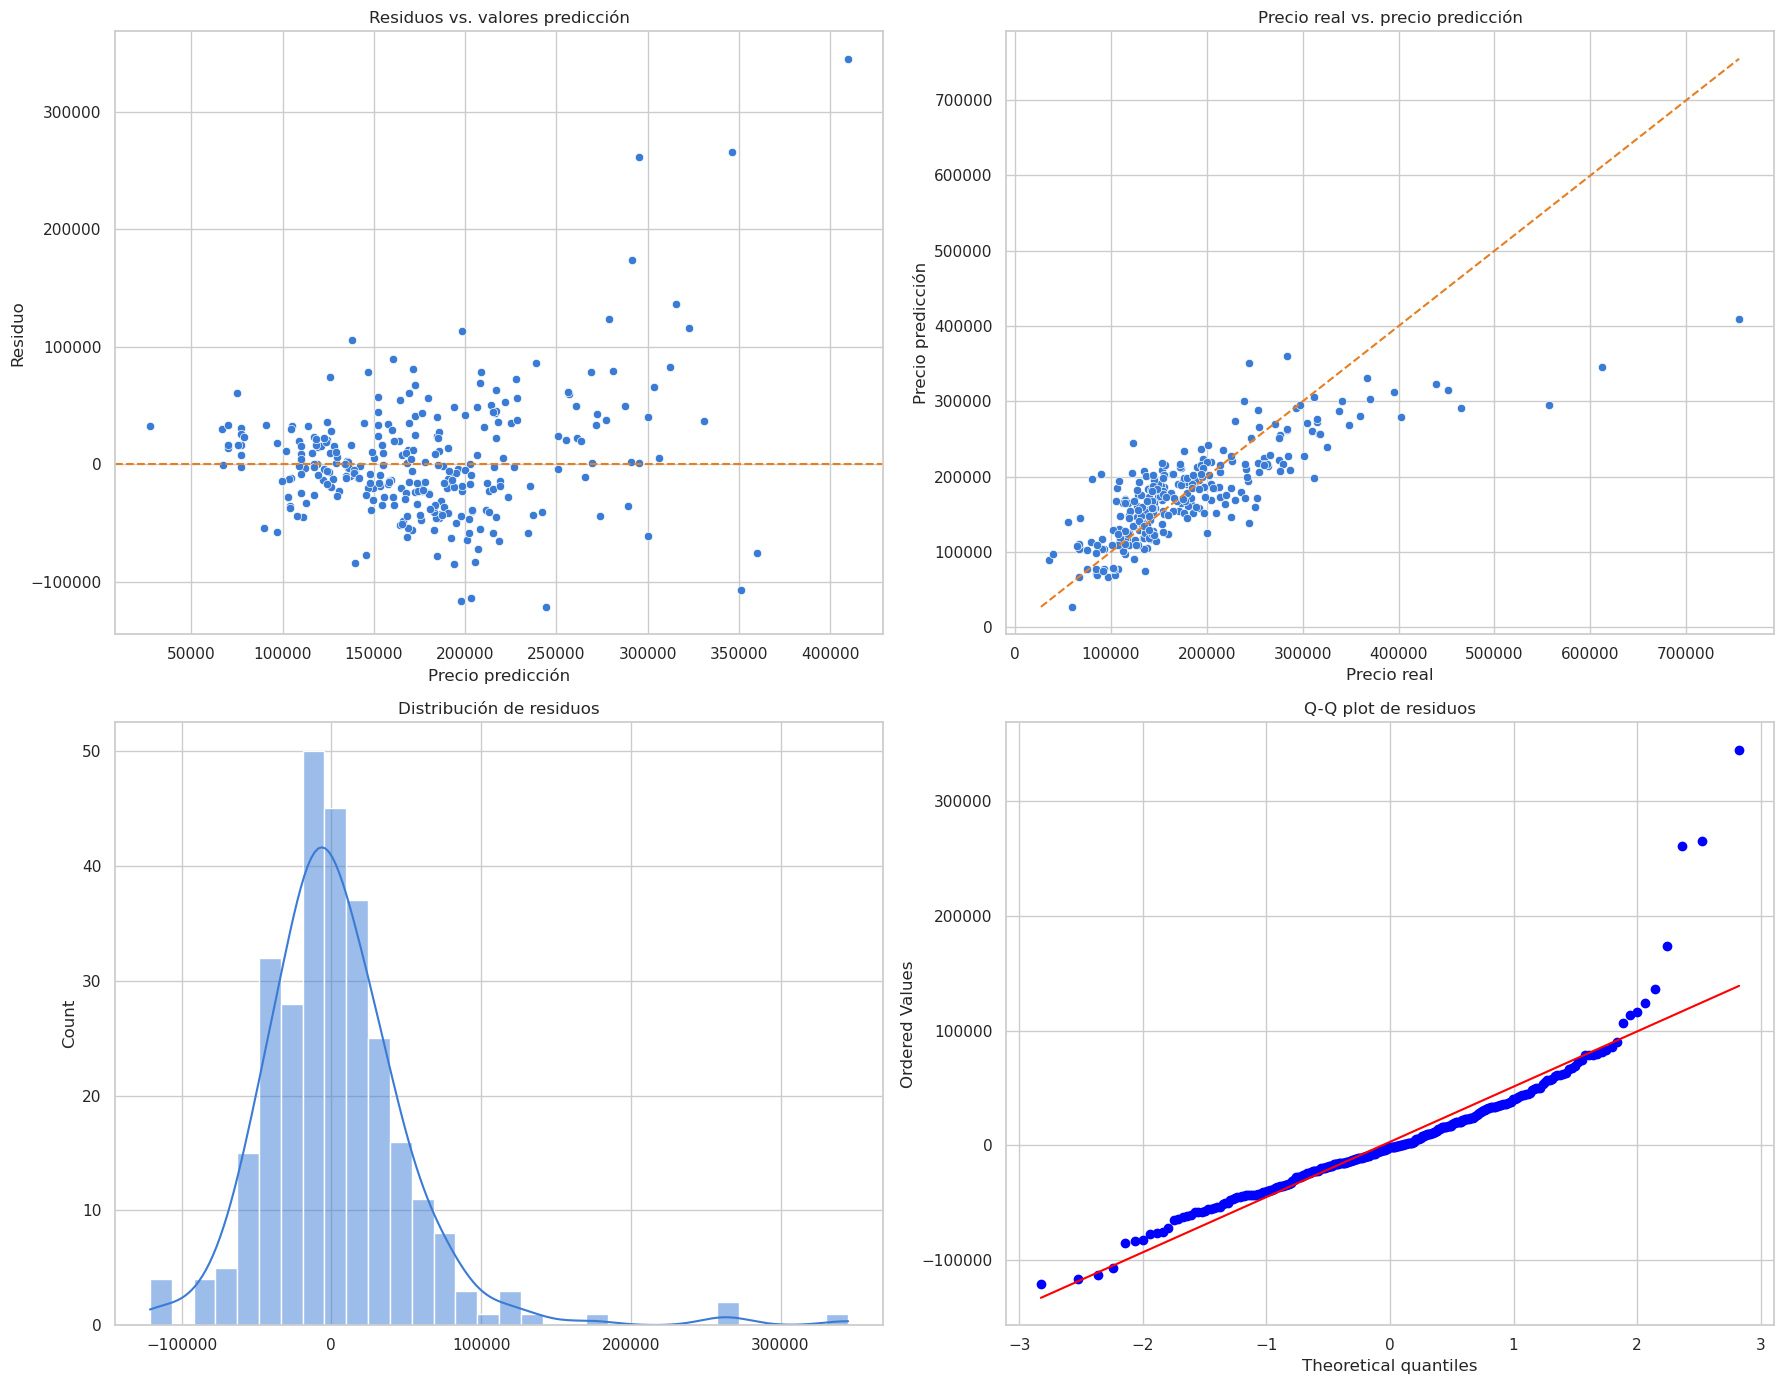

,prueba,estadístico,p_valor
0,Shapiro-Wilk (residuos de prueba),0.8689,0.0000
1,Breusch-Pagan (residuos entrenamiento),178.2635,0.0000


In [24]:
residuos = y_test - pred_test

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

sns.scatterplot(x=pred_test, y=residuos, ax=axes[0, 0], color="#3A7BD5")
axes[0, 0].axhline(0, color="#E67E22", linestyle="--")
axes[0, 0].set_title("Residuos vs. valores predicción")
axes[0, 0].set_xlabel("Precio predicción")
axes[0, 0].set_ylabel("Residuo")

sns.scatterplot(x=y_test, y=pred_test, ax=axes[0, 1], color="#3A7BD5")
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[0, 1].plot(limites, limites, "--", color="#E67E22")
axes[0, 1].set_title("Precio real vs. precio predicción")
axes[0, 1].set_xlabel("Precio real")
axes[0, 1].set_ylabel("Precio predicción")

sns.histplot(residuos, kde=True, ax=axes[1, 0], color="#3A7BD5")
axes[1, 0].set_title("Distribución de residuos")

stats.probplot(residuos, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot de residuos")

plt.tight_layout()
plt.show()

shapiro_res = stats.shapiro(residuos)
bp = het_breuschpagan(modelo_final.resid, modelo_final.model.exog)
diagnosticos = pd.DataFrame({
    "prueba": ["Shapiro-Wilk (residuos de prueba)", "Breusch-Pagan (residuos entrenamiento)"],
    "estadístico": [shapiro_res.statistic, bp[0]],
    "p_valor": [shapiro_res.pvalue, bp[1]],})

display(diagnosticos)

La nube de residuos debe oscilar aleatoriamente alrededor de cero. Un patrón curvo sugeriría falta de linealidad; una dispersión creciente, heterocedasticidad; y separaciones fuertes en el Q-Q plot, falta de normalidad o valores influyentes. Estas pruebas complementan las métricas: un $R^2$ elevado no garantiza que todos los supuestos se cumplan.

**12. Conclusiones.**

1. `SalePrice`, `GrLivArea` y `2ndFlrSF` no siguen una distribución normal. Las pruebas analíticas y las visualizaciones coinciden; en `2ndFlrSF`, la gran cantidad de ceros responde a viviendas sin segundo piso.
2. Las variables más correlacionadas con precio son `OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF` y `1stFlrSF`. Calidad, superficie y garaje concentran la mayor señal lineal.
3. El OLS inicial explica cerca de 81.3% de la variación en la muestra, pero combina variables no significativas y predictores que miden componentes similares de la propiedad.
4. La revisión conjunta de p-valores y VIF reduce el modelo de 36 a 19 variables, conserva prácticamente toda la capacidad explicativa y limita la multicolinealidad a niveles manejables.
5. En datos de prueba, el modelo final alcanza aproximadamente $R^2=0.827$ y RMSE de USD 36,459. Por tanto, ofrece una estimación razonablemente precisa para fines académicos y exploratorios, pero su error todavía es relevante para decisiones inmobiliarias individuales.
6. La siguiente mejora lógica sería incorporar variables categóricas —especialmente vecindario, calidad de cocina, tipo de vivienda y condición de venta— mediante codificación adecuada, estudiar una transformación logarítmica de `SalePrice`, tratar observaciones influyentes y comparar el desempeño mediante validación cruzada.

**Respuesta ejecutiva.**

El modelo es sólido como línea base: explica alrededor de ocho décimas partes de la variación del precio fuera de muestra. No obstante, no debe venderse como tasador definitivo. Los datos respaldan una buena capacidad de orientación, no precisión absoluta. La métrica resume el rendimiento; el análisis de residuos explica dónde y por qué puede fallar.